<a href="https://colab.research.google.com/github/Adityadev1oper/GenAI-Projects/blob/main/Day2TrainedAMiniatureGANs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q troch matplotlib numpy

In [4]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt


In [6]:
torch.manual_seed(42)

In [9]:
def sample_real(batch_size):
  return torch.randn(batch_size,1)*1.5 + 2.0


In [10]:
real_samples = sample_real(1000)

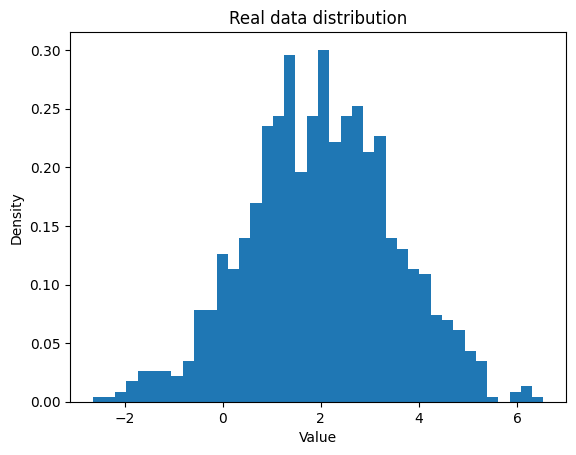

In [14]:
plt.hist(real_samples.numpy().flatten(), bins=40, density=True)
plt.title("Real data distribution")
plt.xlabel("Value")
plt.ylabel("Density")
plt.show()

In [15]:
latent_dim = 5
generator = nn.Sequential(
    nn.Linear(latent_dim, 16),
    nn.ReLU(),
    nn.Linear(16, 16),
    nn.ReLU(),
    nn.Linear(16, 1)
)

In [16]:
discriminator = nn.Sequential(
    nn.Linear(1, 16),
    nn.LeakyReLU(0.2),
    nn.Linear(16, 16),
    nn.LeakyReLU(0.2),
    nn.Linear(16, 1),
    nn.Sigmoid()
)

In [17]:
loss_fn = nn.BCELoss()

g_optimizer = torch.optim.Adam(
    generator.parameters(), lr=0.001
)

d_optimizer = torch.optim.Adam(
    discriminator.parameters(), lr=0.001
)

epochs = 3000
batch_size = 128
g_losses = []
d_losses = []

In [18]:
for epoch in range(epochs):

    # 1. Train the discriminator.
    real = sample_real(batch_size)
    noise = torch.randn(batch_size, latent_dim)

    with torch.no_grad():
        fake = generator(noise)

    real_labels = torch.ones(batch_size, 1)
    fake_labels = torch.zeros(batch_size, 1)

    real_predictions = discriminator(real)
    fake_predictions = discriminator(fake)

    d_loss_real = loss_fn(real_predictions, real_labels)
    d_loss_fake = loss_fn(fake_predictions, fake_labels)

    d_loss = (d_loss_real + d_loss_fake) / 2

    d_optimizer.zero_grad()
    d_loss.backward()
    d_optimizer.step()

    # 2. Train the generator.
    noise = torch.randn(batch_size, latent_dim)
    fake = generator(noise)

    # The generator wants the discriminator to predict "real".
    predictions = discriminator(fake)
    g_loss = loss_fn(predictions, real_labels)

    g_optimizer.zero_grad()
    g_loss.backward()
    g_optimizer.step()

    g_losses.append(g_loss.item())
    d_losses.append(d_loss.item())

    if (epoch + 1) % 500 == 0:
        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"D loss: {d_loss.item():.4f} | "
            f"G loss: {g_loss.item():.4f}"
        )

Epoch 500/3000 | D loss: 0.7055 | G loss: 0.6111
Epoch 1000/3000 | D loss: 0.6707 | G loss: 0.7942
Epoch 1500/3000 | D loss: 0.6782 | G loss: 0.7345
Epoch 2000/3000 | D loss: 0.6859 | G loss: 0.7321
Epoch 2500/3000 | D loss: 0.6899 | G loss: 0.7183
Epoch 3000/3000 | D loss: 0.6881 | G loss: 0.7172


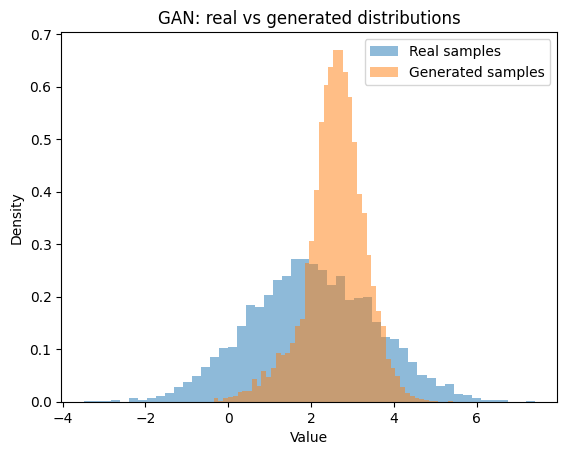

Real mean: 2.018
Generated mean: 2.591
Real standard deviation: 1.506
Generated standard deviation: 0.709


In [19]:
with torch.no_grad():
    noise = torch.randn(5000, latent_dim)
    generated = generator(noise).numpy().flatten()

real = sample_real(5000).numpy().flatten()

plt.hist(
    real, bins=50, density=True,
    alpha=0.5, label="Real samples"
)

plt.hist(
    generated, bins=50, density=True,
    alpha=0.5, label="Generated samples"
)

plt.title("GAN: real vs generated distributions")
plt.xlabel("Value")
plt.ylabel("Density")
plt.legend()
plt.show()

print("Real mean:", round(real.mean(), 3))
print("Generated mean:", round(generated.mean(), 3))
print("Real standard deviation:", round(real.std(), 3))
print("Generated standard deviation:", round(generated.std(), 3))